In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from TOV_Solver import generate_mr_curve
from EOS_construction import constructing_EOS

In [13]:
p, mu, e, cs, mu_c_total, p_c_total, gam_h, gam_q, n_transition, delta_n = constructing_EOS(8,100)

In [14]:
e_total, p_total, mu_total, cs_total, P_crit, mu_crit = e, p, mu, cs, p_c_total, mu_c_total

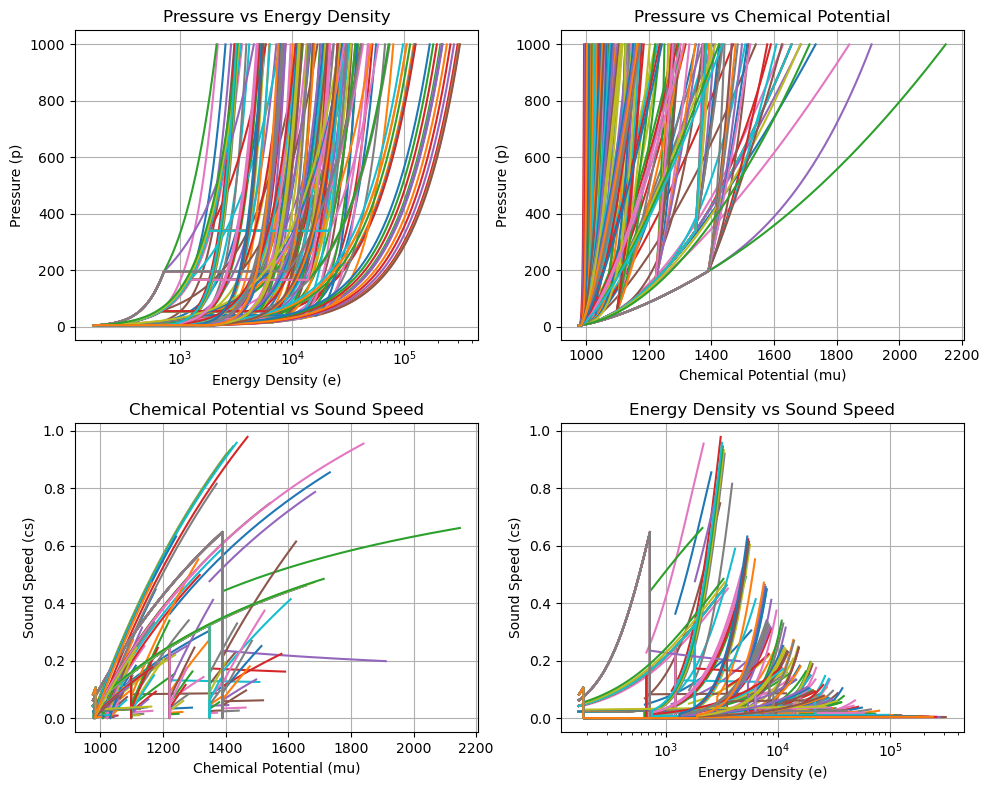

In [15]:
# Create a 2x2 grid of subplots outside the loop to include all curves in one plot
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# After the loop, plot concatenated data
for i in range(len(p)):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].plot(e_total[i], p_total[i])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].set_xscale('log')
#axes[0, 0].set_yscale('log')
axes[0, 0].grid(True)

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].set_xscale('log')
axes[1, 1].grid(True)

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

In [16]:
radii, masses, compacts, love_nums = [0]*len(e_total), [0]*len(e_total), [0]*len(e_total), [0]*len(e_total)

In [17]:
for i in range(len(e_total)):
    e_arr = e_total[i]
    p_arr = p_total[i]
    radii[i], masses[i], compacts[i], love_nums[i] = generate_mr_curve(e_arr, p_arr)

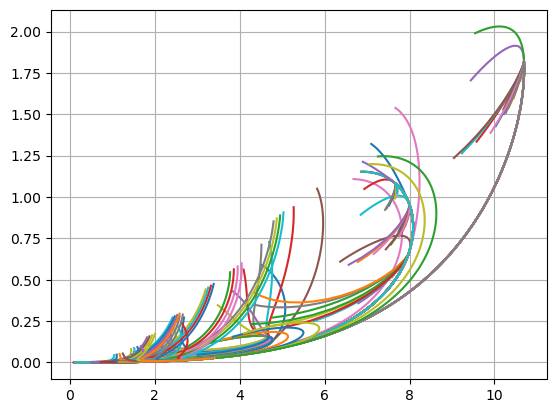

In [18]:
for i in range(len(e_total)):
    plt.plot(radii[i],masses[i])
plt.grid()

In [19]:
len(radii)

162

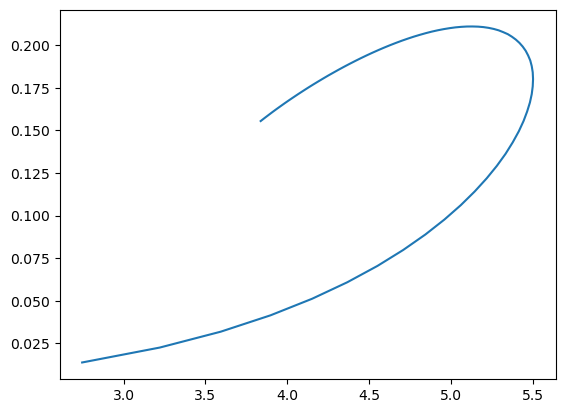

In [23]:
plt.plot(radii[120],masses[120])

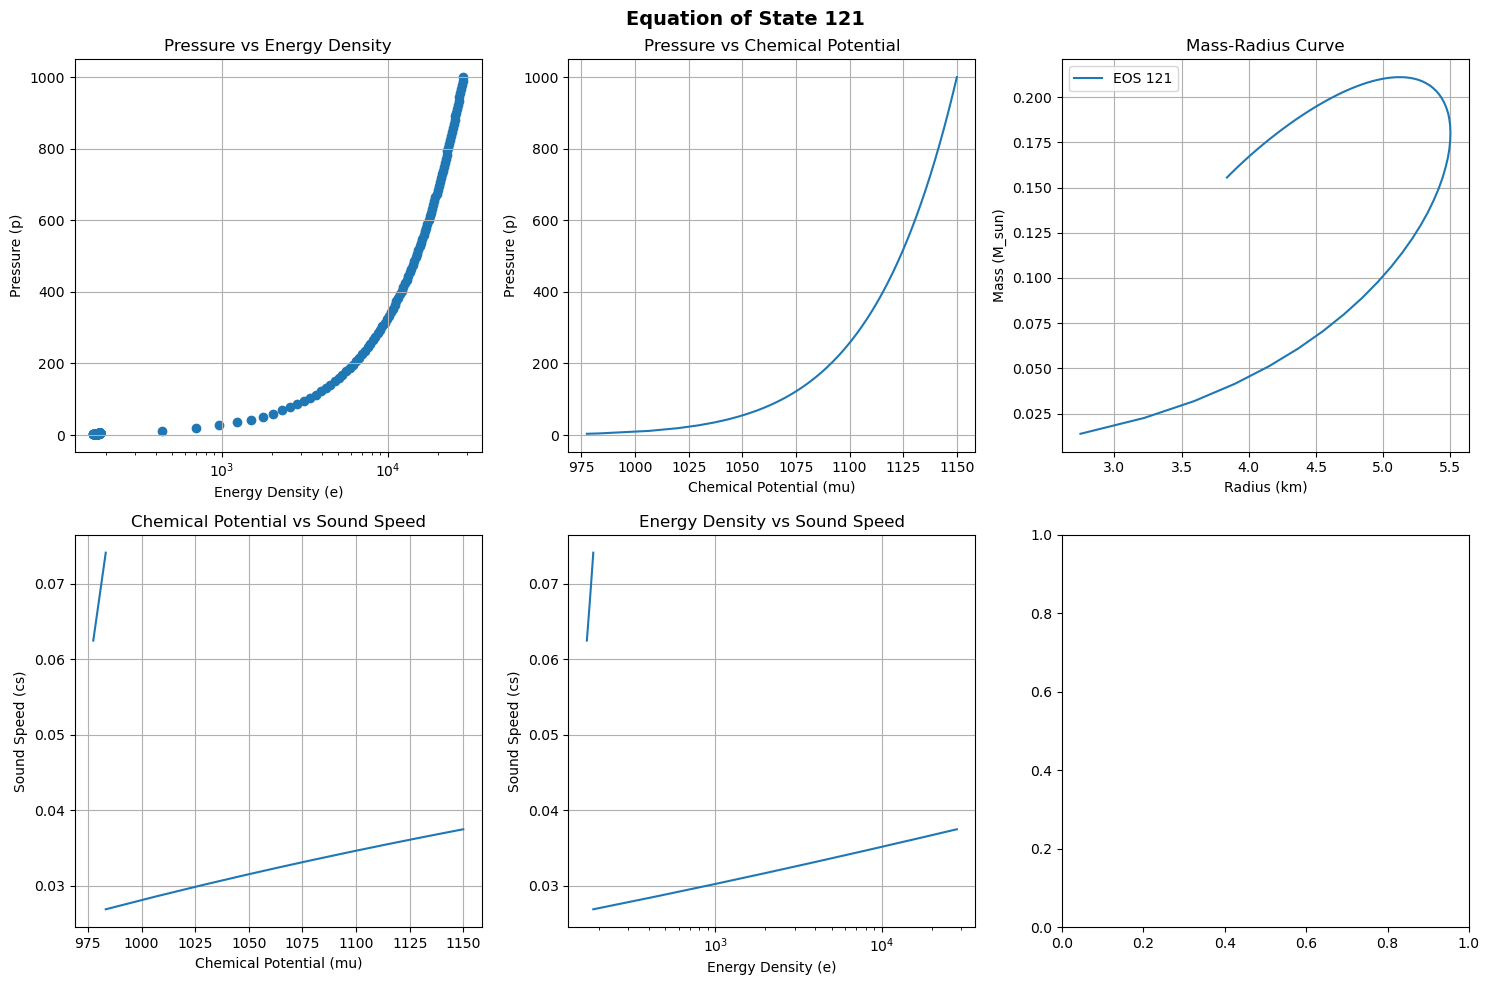

In [26]:
import matplotlib.pyplot as plt

# Specify the EOS index you want to plot (e.g., i = 2)
i = 120 # Change this to the desired EOS number

# Create a 2x3 grid of subplots
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Plot 1: Pressure vs Energy Density
axes[0, 0].scatter(e_total[i], p_total[i])
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].set_xscale('log')
axes[0, 0].grid(True)

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].plot(mu_total[i], p_total[i])
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].plot(mu_total[i], cs_total[i])
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].plot(e_total[i], cs_total[i])
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].set_xscale('log')
axes[1, 1].grid(True)

# Plot 5: Mass-Radius (M-R) Curve
radii, masses, _, _ = generate_mr_curve(e_total[i], p_total[i])  # Compute M-R curve for this EOS
axes[0, 2].plot(radii, masses, label=f'EOS {i+1}')
axes[0, 2].set_title('Mass-Radius Curve')
axes[0, 2].set_xlabel('Radius (km)')
axes[0, 2].set_ylabel('Mass (M_sun)')
axes[0, 2].legend()
axes[0, 2].grid(True)

# Adjust layout and show the plot
plt.suptitle(f'Equation of State {i+1}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [27]:
len(e_total[0])

300

In [34]:
import pandas as pd
import os

In [40]:
masses[i]

0.003565259757388654

In [1]:
import os
import pandas as pd

# Ensure the "EOS" directory exists
output_dir = "EOS"
os.makedirs(output_dir, exist_ok=True)

# List of variable names
variable_names = [
    "e_total", "p_total", "mu_total", "cs_total",
    "radii", "masses", "compacts", "love_nums"
]

variable_data = [e_total, p_total, mu_total, cs_total, radii, masses, compacts, love_nums]

# Iterate over each EOS (each sublist in the nested list structure)
for eos_index, eos_values in enumerate(zip(*variable_data)):  
    # Collect the data for the current EOS, handling different lengths
    data = {}
    for j, name in enumerate(variable_names):
        data[name] = pd.Series(variable_data[j][eos_index])  # Convert to Series for length mismatch handling
    
    # Handle P_crit and mu_crit correctly
    data["P_crit"] = pd.Series(P_crit[eos_index])
    data["mu_crit"] = pd.Series(mu_crit[eos_index])

    # Convert to DataFrame, ensuring missing values are filled with NaN
    df = pd.DataFrame(data)

    # Save to Excel in EOS directory with a unique filename for each EOS
    df.to_excel(os.path.join(output_dir, f"EOS_{eos_index}.xlsx"), index=False)


NameError: name 'e_total' is not defined